# Overview (PyTorch Edition)
> **Chuyển đổi từ Keras sang PyTorch** — Thành viên 1: Lý Hồng Hưng (MSSV: 3123411132)
- **MNIST dataset**:
  + Goal: Recognizing handwritten digits
  + Input: a 28x28 grayscale image
  + Output: class label (0, 1, ..., 9)
- Defining an MLP (`nn.Module`) for MNIST
- Training and evaluating an MLP in PyTorch
- Extracting intermediate features (`fc2`) via `forward()` / forward hooks

# Import libraries

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Tùy chọn: cài đặt torchinfo nếu chưa có (dùng thay cho model.summary() trong Keras)
try:
    from torchinfo import summary
except ImportError:
    summary = None
    print("Gợi ý: cài đặt torchinfo bằng lệnh `pip install torchinfo` để hiển thị bảng tóm tắt chi tiết.")

# Cố định seed và chọn thiết bị
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Using device   :", device)

Gợi ý: cài đặt torchinfo bằng lệnh `pip install torchinfo` để hiển thị bảng tóm tắt chi tiết.
PyTorch version: 2.14.1+cu130
Using device   : cuda


In [2]:
num_classes = 10   # 10 classes: 0, 1, ..., 9

# (1) Data

In [3]:
# Tải tập dữ liệu MNIST bằng torchvision
# transforms.ToTensor() tự động chuyển ảnh PIL (28, 28) giá trị [0, 255] sang Tensor (1, 28, 28) float32 trong [0.0, 1.0]
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

print(len(train_dataset), 'train samples')
print(len(test_dataset), 'test samples')

# Lưu ý quan trọng khi chuyển Keras -> PyTorch:
# Trong Keras: dùng keras.utils.to_categorical(y, 10) tạo one-hot vector kết hợp categorical_crossentropy.
# Trong PyTorch: nn.CrossEntropyLoss() nhận trực tiếp nhãn số nguyên (0..9, kiểu torch.long), không cần one-hot!
# Minh họa hàm one-hot tương đương trong PyTorch (nếu cần):
print("Example one-hot for label 2 (3 classes):", F.one_hot(torch.tensor(2), num_classes=3))

100%|██████████| 9.91M/9.91M [00:00<00:00, 60.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.76MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.5MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 18.1MB/s]

60000 train samples
10000 test samples
Example one-hot for label 2 (3 classes): tensor([0, 0, 1])


# (2) Declare model

In [4]:
class MNIST_MLP(nn.Module):
    """Kiến trúc MLP cho MNIST (chuyển đổi 1:1 từ Keras):
    Input (1, 28, 28) -> Flatten (784) -> FC1 (512, ReLU) -> Dropout(0.2)
                      -> FC2 (512, ReLU) -> Dropout(0.2) -> FC3 (10 logits)
    """
    def __init__(self, num_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 512)
        self.dropout1 = nn.Dropout(p=0.2)
        self.fc2 = nn.Linear(512, 512)
        self.dropout2 = nn.Dropout(p=0.2)
        self.fc3 = nn.Linear(512, num_classes)  # Không đặt Softmax vì nn.CrossEntropyLoss đã tích hợp LogSoftmax

    def forward(self, x, return_fc2=False):
        x = self.flatten(x)
        x = F.relu(self.fc1(x))
        x = self.dropout1(x)
        feat_fc2 = F.relu(self.fc2(x))
        x = self.dropout2(feat_fc2)
        logits = self.fc3(x)
        if return_fc2:
            return feat_fc2, logits
        return logits


model = MNIST_MLP(num_classes=num_classes).to(device)
print(model)

# In tóm tắt kiến trúc & số lượng tham số (tương đương model.summary() trong Keras)
if summary is not None:
    print(summary(model, input_size=(1, 1, 28, 28), device=device))
else:
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total params: {total_params:,} | Trainable params: {trainable_params:,}")

MNIST_MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=512, bias=True)
  (dropout1): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=512, out_features=512, bias=True)
  (dropout2): Dropout(p=0.2, inplace=False)
  (fc3): Linear(in_features=512, out_features=10, bias=True)
)
Total params: 669,706 | Trainable params: 669,706


# (3) Train defined model
- Lịch sử huấn luyện (`train_loss`, `train_acc`, `val_loss`, `val_acc`) được lưu vào dictionary `history`.
- Nếu máy bị thiếu bộ nhớ (OOM), hãy giảm `batch_size`.

In [5]:
# Khai báo siêu tham số, hàm mất mát và bộ tối ưu (giống bản Keras gốc)
batch_size = 128
epochs = 30
lr = 0.01

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

history = {
    "loss": [],
    "accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}


def evaluate(model, loader, criterion, device):
    """Đánh giá loss và accuracy trên một DataLoader (tương đương model.evaluate)."""
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total


starting_time = time.time()
for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total
    val_loss, val_acc = evaluate(model, test_loader, criterion, device)

    history["loss"].append(train_loss)
    history["accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    print(f"Epoch {epoch:02d}/{epochs} - loss: {train_loss:.4f} - accuracy: {train_acc:.4f} - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

print('> training time is %.4f minutes' % ((time.time() - starting_time) / 60))

Epoch 01/30 - loss: 2.1135 - accuracy: 0.4943 - val_loss: 1.6615 - val_accuracy: 0.7226
Epoch 02/30 - loss: 1.0863 - accuracy: 0.7574 - val_loss: 0.6645 - val_accuracy: 0.8483
Epoch 03/30 - loss: 0.6076 - accuracy: 0.8360 - val_loss: 0.4662 - val_accuracy: 0.8786
Epoch 04/30 - loss: 0.4854 - accuracy: 0.8634 - val_loss: 0.3931 - val_accuracy: 0.8921
Epoch 05/30 - loss: 0.4287 - accuracy: 0.8766 - val_loss: 0.3538 - val_accuracy: 0.9005
Epoch 06/30 - loss: 0.3923 - accuracy: 0.8884 - val_loss: 0.3305 - val_accuracy: 0.9067
Epoch 07/30 - loss: 0.3680 - accuracy: 0.8941 - val_loss: 0.3102 - val_accuracy: 0.9101
Epoch 08/30 - loss: 0.3477 - accuracy: 0.9005 - val_loss: 0.2960 - val_accuracy: 0.9154
Epoch 09/30 - loss: 0.3298 - accuracy: 0.9049 - val_loss: 0.2817 - val_accuracy: 0.9193
Epoch 10/30 - loss: 0.3164 - accuracy: 0.9086 - val_loss: 0.2700 - val_accuracy: 0.9222
Epoch 11/30 - loss: 0.3006 - accuracy: 0.9123 - val_loss: 0.2583 - val_accuracy: 0.9254
Epoch 12/30 - loss: 0.2893 - acc

### Vẽ biểu đồ quá trình huấn luyện (Loss & Accuracy)

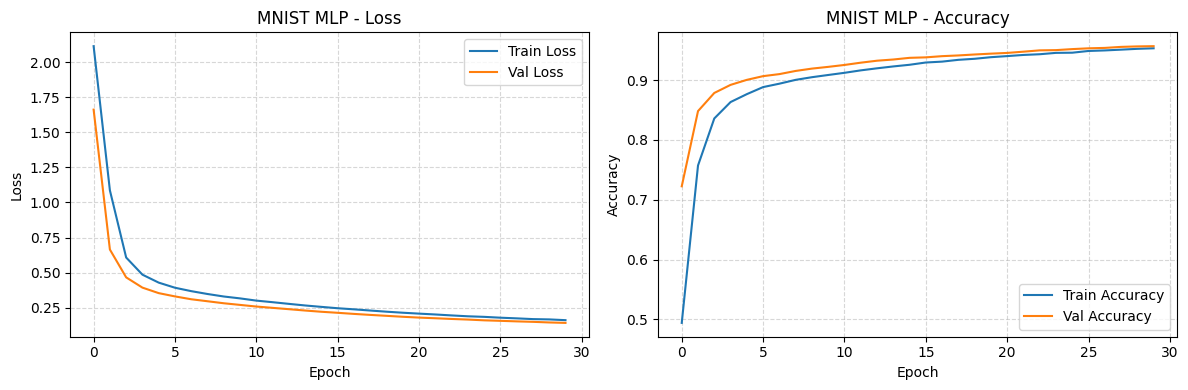

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].set_title("MNIST MLP - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(history["accuracy"], label="Train Accuracy")
axes[1].plot(history["val_accuracy"], label="Val Accuracy")
axes[1].set_title("MNIST MLP - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Tham khảo thời gian huấn luyện bản Keras gốc
- GTX 1080: ~1.4402 phút / 30 epochs (Test accuracy ~96.48% – 96.57%)
- Core i7: ~3.0493 phút / 30 epochs

# (4) Evaluate trained model

In [7]:
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)

Test loss: 0.14184692357182502
Test accuracy: 0.9568


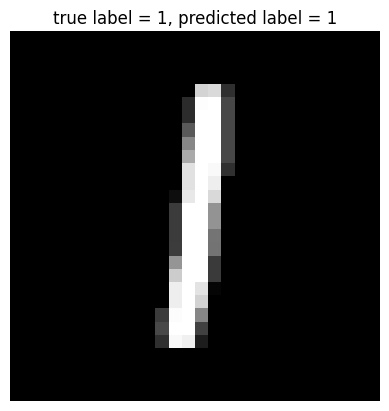

In [8]:
# Chọn ngẫu nhiên một ảnh kiểm tra và dự đoán bằng mô hình PyTorch
random_test_index = np.random.choice(len(test_dataset), size=1)[0]
test_img_tensor, test_label = test_dataset[random_test_index]  # shape: (1, 28, 28)

model.eval()
with torch.no_grad():
    # Thêm chiều batch: (1, 28, 28) -> (1, 1, 28, 28)
    logits = model(test_img_tensor.unsqueeze(0).to(device))
    probs = F.softmax(logits, dim=1)
    pred_label = probs.argmax(dim=1).item()

plt.imshow(test_img_tensor.squeeze(0).numpy(), cmap='gray')
plt.title(f'true label = {test_label}, predicted label = {pred_label}')
plt.axis('off')
plt.show()

### Kiểm tra chi tiết kích thước tensor & xác suất đầu ra (tương ứng các cell kiểm tra trong bản gốc)

True label            : 6
Single image shape    : (1, 28, 28)
Input batch shape     : (1, 1, 28, 28)
y_pred shape          : (1, 10)
Sum of probabilities  : [0.9999999]
Predicted class argmax: [6]


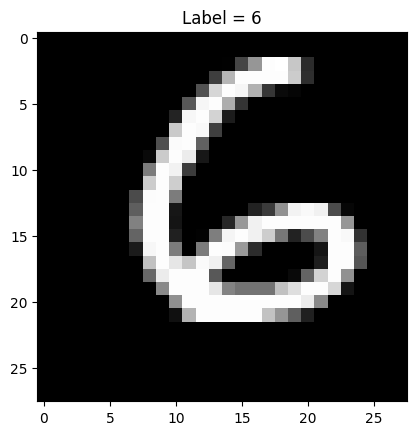

In [9]:
random_test_index = np.random.choice(len(test_dataset), size=1)[0]
test_img_tensor, test_label = test_dataset[random_test_index]

print("True label            :", test_label)
print("Single image shape    :", tuple(test_img_tensor.shape))          # (1, 28, 28)
input_batch = test_img_tensor.unsqueeze(0).to(device)
print("Input batch shape     :", tuple(input_batch.shape))              # (1, 1, 28, 28)

model.eval()
with torch.no_grad():
    logits = model(input_batch)
    y_pred = F.softmax(logits, dim=1).cpu().numpy()

print("y_pred shape          :", y_pred.shape)                          # (1, 10)
print("Sum of probabilities  :", np.sum(y_pred, axis=1))                # ~[1.0]
print("Predicted class argmax:", np.argmax(y_pred, axis=1))

plt.imshow(test_img_tensor.squeeze(0).numpy(), cmap='gray')
plt.title(f"Label = {test_label}")
plt.show()

### Trích xuất đặc trưng từ lớp ẩn `fc2` (tương đương `Model(inputs=model.input, outputs=[model.get_layer("fc2").output, model.output])` trong Keras)
Trong PyTorch có 2 cách phổ biến:
1. Trả về trực tiếp trong hàm `forward(x, return_fc2=True)`.
2. Đăng ký **Forward Hook** (`register_forward_hook`) mà không cần sửa cấu trúc hàm `forward()`.

In [10]:
# Cách 1: Sử dụng cờ return_fc2=True trong forward()
model.eval()
with torch.no_grad():
    y_feat_t, logits_t = model(input_batch, return_fc2=True)
    y_feat = y_feat_t.cpu().numpy()
    y_pred = F.softmax(logits_t, dim=1).cpu().numpy()

print("Cách 1 - y_feat shape:", y_feat.shape, "| y_pred shape:", y_pred.shape)
print("50 giá trị đầu của vector đặc trưng fc2:\n", y_feat[0, :50])

Cách 1 - y_feat shape: (1, 512) | y_pred shape: (1, 10)
50 giá trị đầu của vector đặc trưng fc2:
 [1.0504237  0.         0.34292576 1.1249777  0.845786   0.
 0.41639268 0.08595964 0.46016616 0.         0.84277487 0.19373213
 1.2196838  0.19950777 0.47197556 0.6347281  1.2567719  0.2006403
 0.         0.         0.         0.8486126  0.         0.
 0.02663948 1.4842935  0.85111403 0.33617488 0.25011086 0.
 0.6352022  0.         0.         1.1983844  0.2612181  0.
 0.         0.35000685 0.         0.17738321 0.         0.
 0.54302704 0.4589079  0.         0.         0.03855577 0.27654085
 0.         0.        ]


In [11]:
# Cách 2: Sử dụng register_forward_hook (linh hoạt cho mọi lớp bất kỳ giống model.get_layer)
extracted = {}

def hook_fn(module, inp, out):
    extracted["fc2"] = F.relu(out).detach().cpu().numpy()

handle = model.fc2.register_forward_hook(hook_fn)
model.eval()
with torch.no_grad():
    _ = model(input_batch)
handle.remove()  # Luôn gỡ hook sau khi sử dụng

print("Cách 2 (Forward Hook) - fc2 shape:", extracted["fc2"].shape)
print("Khớp tuyệt đối giữa Cách 1 và Cách 2:", np.allclose(y_feat, extracted["fc2"]))

Cách 2 (Forward Hook) - fc2 shape: (1, 512)
Khớp tuyệt đối giữa Cách 1 và Cách 2: True
